## TODO

- Write a disclaimer note to state that we are using 2d_convolution branch of corgisim to generate the dataset. 

- Write the script to get the cubes in here, and read from the headers or the dictionary to set up the valid positions in here

- Set up the plots for the core_throughput with the highest sampling we have 

- I need to push a minor update on the branch and release the new psf cubes for convolution

- Put all local functions to the python module (core_throughput_plotting, core_throughput_analysis)


In [1]:
# Import the library to here.
from astropy.io import fits
import os
from corgisim import convolution, prf_simulation
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

In [ ]:
# data path
data_path =
corgi_prf_cube_no_fpm_fname = 'prf_hlc_band_1_no_fpm_small.fits'
corgi_prf_cube_fname = 'prf_hlc_band_1_psf_small.fits'

In [20]:
# Load the data cube in here
corgi_prf_cubes = fits.getdata(os.path.join(data_path, corgi_prf_cube_fname))
no_fpm_psf_cube = fits.getdata(os.path.join(data_path, corgi_prf_cube_no_fpm_fname))

In [31]:
# Get the simulation infomation for the psf positions 
prf_sim_info = prf_simulation._get_prf_sim_info(os.path.join(data_path, corgi_prf_cube_fname)) # Get the simulation information 

# 1. Get the radii grids for convolution 
radii_lamD, _ = convolution.build_radial_grid(
    prf_sim_info['iwa'], 
    prf_sim_info['owa'], 
    prf_sim_info['inner_step'], 
    prf_sim_info['mid_step'], 
    prf_sim_info['outer_step'],
    prf_sim_info['max_radius']
)

# 2. Get the azimuth grid for convolution
azimuths_deg, _ = convolution.build_azimuth_grid(prf_sim_info['step_deg'])

# 3. positions of the psfs 
valid_positions = convolution.get_valid_polar_positions(radii_lamD, azimuths_deg)

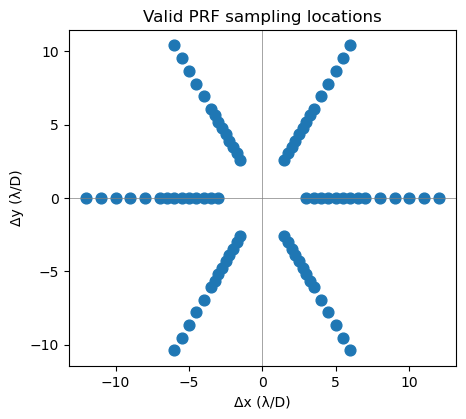

Number of valid PRF sampling locations: 84


In [32]:
# First we check where the PSFs are at

# TODO - turn this into a function

# Unpack to arrays
r_vals = np.array([r for r, th in valid_positions])
theta_vals = np.array([th.to_value(u.rad) for r, th in valid_positions])

# Convert to Cartesian coordinates (λ/D)
x = r_vals * np.cos(theta_vals)
y = r_vals * np.sin(theta_vals)

# Plot
plt.figure(figsize=(5, 5))
plt.scatter(x, y, s=60)

plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)

plt.gca().set_aspect("equal")
plt.xlabel("Δx (λ/D)")
plt.ylabel("Δy (λ/D)")
plt.title("Valid PRF sampling locations")

plt.show()

print(f"Number of valid PRF sampling locations: {len(valid_positions)}")

In [33]:
# we compute the core throughput

from core_throughput_analysis import *

tau_cgperf_small, debug_cgperf_small = compute_core_throughput_half_max(
    corgi_prf_cubes,
    no_fpm_psf_cube,
    valid_positions,
    return_debug=True,
)

tau_circular_small, debug_circular_small = compute_core_throughput_fixed_aperture(
    corgi_prf_cubes,
    no_fpm_psf_cube,
    valid_positions,
    pixel_scale_mas=21.8,
    lambda_d_mas=50.0,
    core_radius_ld=.5,
    return_debug=True,
)

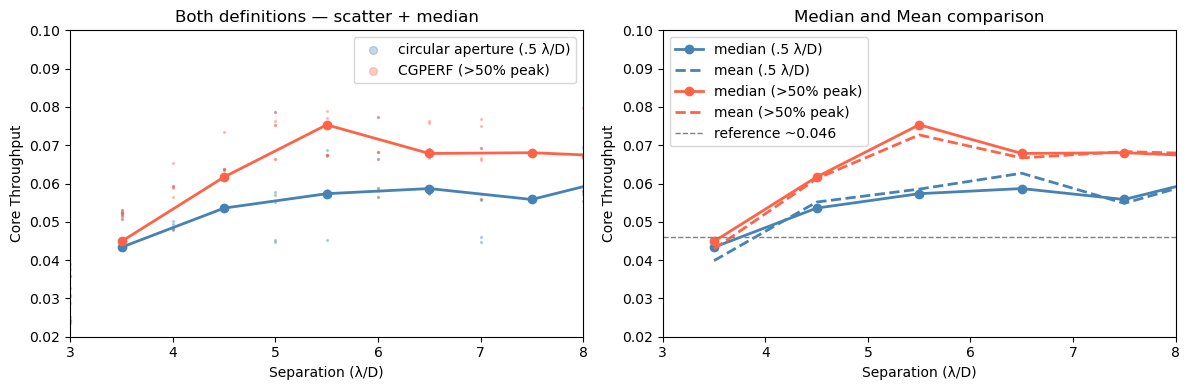

   Sep     circular       cgperf
   3.5       0.0434       0.0449
   4.5       0.0536       0.0617
   5.5       0.0573       0.0753
   6.5       0.0587       0.0679
   7.5       0.0558       0.0680
   8.5       0.0625       0.0669
   9.5       0.0595       0.0669
  10.5       0.0069       0.0069


In [34]:

# ── radial binning ─────────────────────────────────────────────────────────
rho_ld, _ = parse_sample_positions(valid_positions)
r_bins = np.arange(3.0, 12.0, 1)
bin_centres = (r_bins[:-1] + r_bins[1:]) / 2

med_circular_small = radial_median(tau_circular_small, rho_ld, r_bins)
med_cgperf_small   = radial_median(tau_cgperf_small,   rho_ld, r_bins)

mean_circular_small = radial_mean(tau_circular_small, rho_ld, r_bins)
mean_cgperf_small   = radial_mean(tau_cgperf_small,   rho_ld, r_bins)

# ── plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

# left: scatter + median for both
axes[0].scatter(rho_ld, tau_circular_small, s=2, alpha=0.3, color='steelblue', label='circular aperture (.5 λ/D)')
axes[0].scatter(rho_ld, tau_cgperf_small,   s=2, alpha=0.3, color='tomato',    label='CGPERF (>50% peak)')
axes[0].plot(bin_centres, med_circular_small, 'o-', color='steelblue', lw=2)
axes[0].plot(bin_centres, med_cgperf_small,   'o-', color='tomato',    lw=2)
axes[0].set_xlim(3, 8)
axes[0].set_ylim(0.02, 0.1)
axes[0].set_xlabel("Separation (λ/D)")
axes[0].set_ylabel("Core Throughput")
axes[0].set_title("Both definitions — scatter + median")
axes[0].legend(markerscale=4)

# right: median only, zoomed for comparison
axes[1].plot(bin_centres, med_circular_small, 'o-', color='steelblue', lw=2, label='median (.5 λ/D)')
axes[1].plot(bin_centres, mean_circular_small, '--', color='steelblue', lw=2, label='mean (.5 λ/D)')
axes[1].plot(bin_centres, med_cgperf_small,   'o-', color='tomato',    lw=2, label='median (>50% peak)')
axes[1].plot(bin_centres, mean_cgperf_small,   '--', color='tomato',    lw=2, label='mean (>50% peak)')
axes[1].axhline(0.046, color='gray', lw=1, linestyle='--', label='reference ~0.046')
axes[1].set_xlim(3, 8)
axes[1].set_ylim(0.02, 0.1)
axes[1].set_xlabel("Separation (λ/D)")
axes[1].set_ylabel("Core Throughput")
axes[1].set_title("Median and Mean comparison")
axes[1].legend(
    # loc='lower right',
    # bbox_to_anchor=(1.02, 0.5),
    # borderaxespad=0.0
)

plt.tight_layout()
plt.show()

# ── quick stats ────────────────────────────────────────────────────────────
print(f"{'Sep':>6} {'circular':>12} {'cgperf':>12}")
for sep, mc, mg in zip(bin_centres, med_circular_small, med_cgperf_small):
    print(f"{sep:>6.1f} {mc:>12.4f} {mg:>12.4f}")

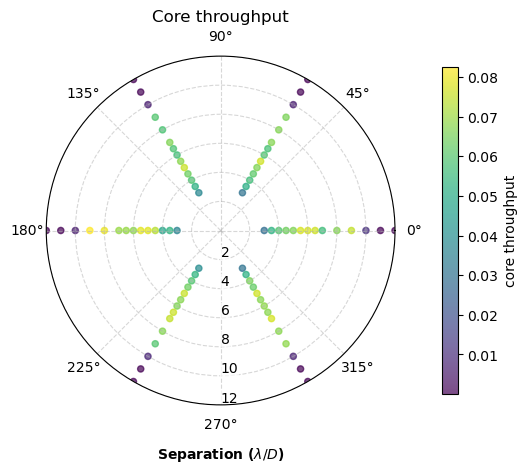

In [35]:
# plot the core throughput as a function of the position in the grid, to see if there are any trends with azimuth or radius

# Polar plot of throughput at sampled positions
rho_ld, theta_deg = parse_sample_positions(valid_positions)

# keep only finite throughput values
m = np.isfinite(tau_cgperf_small)

fig, ax = plt.subplots(figsize=(6, 5), subplot_kw={"projection": "polar"})

sc = ax.scatter(
    np.deg2rad(theta_deg[m]),
    rho_ld[m],
    c=tau_cgperf_small[m],
    cmap="viridis",
    s=20,
    alpha=0.7,
)

ax.set_theta_zero_location("E")   # 0 deg along +x
ax.set_theta_direction(1)         # counter-clockwise
ax.set_title("Core throughput")

# radial-axis label on the 90° line


rmax = np.nanmax(rho_ld[m])
ax.set_ylim(0, rmax)

ax.text(
    np.deg2rad(270),
    rmax + 4,
    r"Separation ($\lambda / D$)",
    ha="center",
    va="bottom",
    clip_on=False,
    fontweight="bold"
)

ax.set_rlabel_position(270)
# 2. Add a white background to the radial tick numbers
plt.draw() # Required to populate tick labels before modifying them
for label in ax.get_yticklabels():
    label.set_bbox(dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5))

    
ax.grid(True, linestyle='--', alpha=0.5)

cbar = plt.colorbar(sc, ax=ax, pad=0.1, shrink=0.85)
cbar.set_label("core throughput")
plt.show()


Text(0.5, 1.0, 'coro, tau=0.0235')

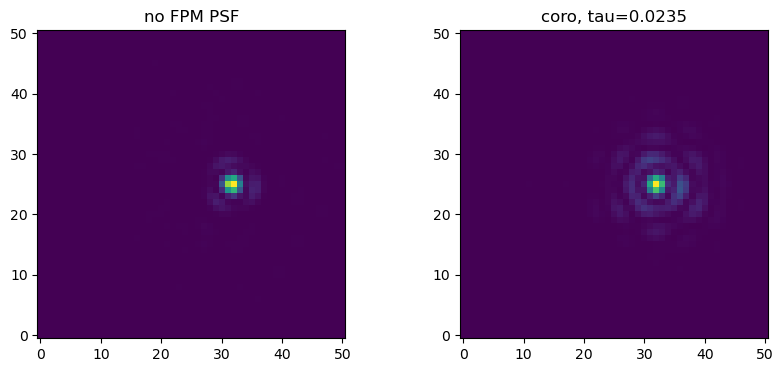

In [36]:
working_zone = (rho_ld >= 2.0) & (rho_ld <= 12.0)

idx = np.where(working_zone & (rho_ld >= 3.0) & (rho_ld < 4.0))[0][0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(no_fpm_psf_cube[idx], origin='lower')
axes[0].set_title(f'no FPM PSF')
axes[1].imshow(corgi_prf_cubes[idx], origin='lower')
axes[1].set_title(f'coro, tau={tau_circular_small[idx]:.4f}')

Text(0.5, 1.0, 'Core throughput (>50% peak)')

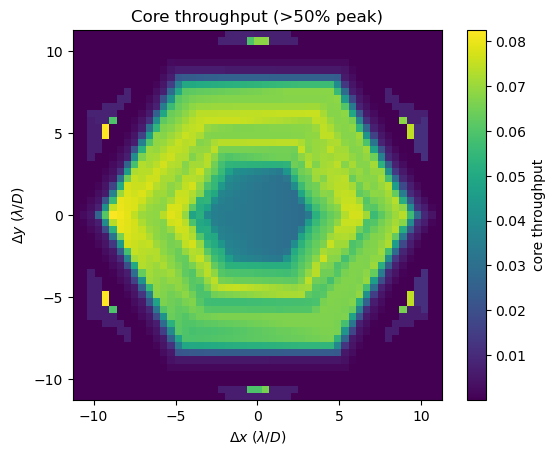

In [39]:
# now plot the core throughput as a function of the position in the grid, to see if there are any trends with azimuth or radius

tau_core_img = interpolate_throughput_map(
    tau_cgperf_small,
    valid_positions,
    image_shape=(51, 51),
    pixel_scale_mas=21.8,
    lambda_d_mas=49.3,
)

ld_per_pixel = 21.8 / 49.3
Ny_img, Nx_img = tau_core_img.shape

extent = [
    -0.5 * Nx_img * ld_per_pixel,
     0.5 * Nx_img * ld_per_pixel,
    -0.5 * Ny_img * ld_per_pixel,
     0.5 * Ny_img * ld_per_pixel,
]

plt.imshow(tau_core_img, origin='lower', extent=extent)
plt.colorbar(label='core throughput')
plt.xlabel(r'$\Delta x$ ($\lambda/D$)')
plt.ylabel(r'$\Delta y$ ($\lambda/D$)')
plt.title('Core throughput (>50% peak)')

Now check the cubes with higher sampling

In [ ]:
# data path
data_path = 
corgi_prf_cube_no_fpm_fname = 'prf_hlc_band_1_no_fpm.fits'
corgi_prf_cube_fname = 'prf_hlc_band_1_psf.fits'


In [49]:
# Load the data cube in here
corgi_prf_cubes = fits.getdata(os.path.join(data_path, corgi_prf_cube_fname))
no_fpm_psf_cube = fits.getdata(os.path.join(data_path, corgi_prf_cube_no_fpm_fname))

In [50]:
# Get the simulation infomation for the psf positions 
prf_sim_info = prf_simulation._get_prf_sim_info(os.path.join(data_path, corgi_prf_cube_fname)) # Get the simulation information 

# 1. Get the radii grids for convolution 
radii_lamD, _ = convolution.build_radial_grid(
    prf_sim_info['iwa'], 
    prf_sim_info['owa'], 
    prf_sim_info['inner_step'], 
    prf_sim_info['mid_step'], 
    prf_sim_info['outer_step'],
    prf_sim_info['max_radius']
)

# 2. Get the azimuth grid for convolution
azimuths_deg, _ = convolution.build_azimuth_grid(prf_sim_info['step_deg'])

# 3. positions of the psfs 
valid_positions = convolution.get_valid_polar_positions(radii_lamD, azimuths_deg)

In [51]:
tau_cgperf, debug_cgperf = compute_core_throughput_half_max(
    corgi_prf_cubes,
    no_fpm_psf_cube,
    valid_positions,
    return_debug=True,
)

tau_circular, debug_circular = compute_core_throughput_fixed_aperture(
    corgi_prf_cubes,
    no_fpm_psf_cube,
    valid_positions,
    pixel_scale_mas=21.8,
    lambda_d_mas=50.0,
    core_radius_ld=.5,
    return_debug=True,
)

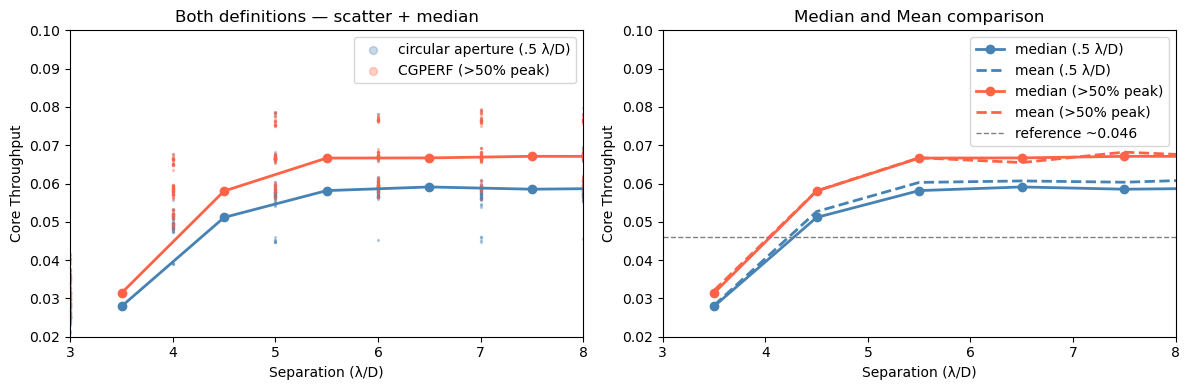

   Sep     circular       cgperf
   3.5       0.0434       0.0449
   4.5       0.0536       0.0617
   5.5       0.0573       0.0753
   6.5       0.0587       0.0679
   7.5       0.0558       0.0680
   8.5       0.0625       0.0669
   9.5       0.0595       0.0669
  10.5       0.0069       0.0069


In [53]:
# ── radial binning ─────────────────────────────────────────────────────────
rho_ld, _ = parse_sample_positions(valid_positions)
r_bins = np.arange(3.0, 12.0, 1)
bin_centres = (r_bins[:-1] + r_bins[1:]) / 2

med_circular = radial_median(tau_circular, rho_ld, r_bins)
med_cgperf  = radial_median(tau_cgperf,   rho_ld, r_bins)

mean_circular = radial_mean(tau_circular, rho_ld, r_bins)
mean_cgperf   = radial_mean(tau_cgperf,   rho_ld, r_bins)

# ── plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

# left: scatter + median for both
axes[0].scatter(rho_ld, tau_circular, s=2, alpha=0.3, color='steelblue', label='circular aperture (.5 λ/D)')
axes[0].scatter(rho_ld, tau_cgperf,   s=2, alpha=0.3, color='tomato',    label='CGPERF (>50% peak)')
axes[0].plot(bin_centres, med_circular, 'o-', color='steelblue', lw=2)
axes[0].plot(bin_centres, med_cgperf,   'o-', color='tomato',    lw=2)
axes[0].set_xlim(3, 8)
axes[0].set_ylim(0.02, 0.1)
axes[0].set_xlabel("Separation (λ/D)")
axes[0].set_ylabel("Core Throughput")
axes[0].set_title("Both definitions — scatter + median")
axes[0].legend(markerscale=4)

# right: median only, zoomed for comparison
axes[1].plot(bin_centres, med_circular, 'o-', color='steelblue', lw=2, label='median (.5 λ/D)')
axes[1].plot(bin_centres, mean_circular, '--', color='steelblue', lw=2, label='mean (.5 λ/D)')
axes[1].plot(bin_centres, med_cgperf,   'o-', color='tomato',    lw=2, label='median (>50% peak)')
axes[1].plot(bin_centres, mean_cgperf,   '--', color='tomato',    lw=2, label='mean (>50% peak)')
axes[1].axhline(0.046, color='gray', lw=1, linestyle='--', label='reference ~0.046')
axes[1].set_xlim(3, 8)
axes[1].set_ylim(0.02, 0.1)
axes[1].set_xlabel("Separation (λ/D)")
axes[1].set_ylabel("Core Throughput")
axes[1].set_title("Median and Mean comparison")
axes[1].legend(
    # loc='lower right',
    # bbox_to_anchor=(1.02, 0.5),
    # borderaxespad=0.0
)

plt.tight_layout()
plt.show()

# ── quick stats ────────────────────────────────────────────────────────────
print(f"{'Sep':>6} {'circular':>12} {'cgperf':>12}")
for sep, mc, mg in zip(bin_centres, med_circular_small, med_cgperf_small):
    print(f"{sep:>6.1f} {mc:>12.4f} {mg:>12.4f}")

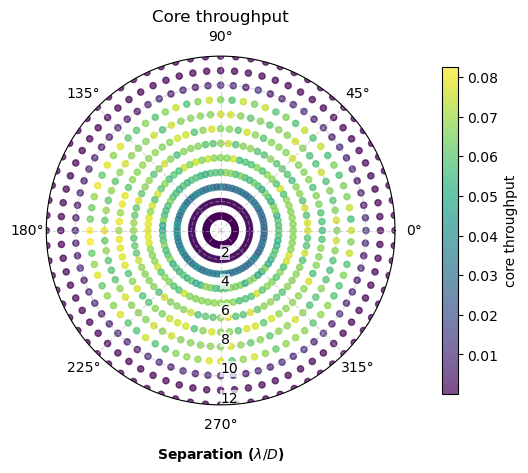

In [55]:
# Polar plot of throughput at sampled positions
rho_ld, theta_deg = parse_sample_positions(valid_positions)

# keep only finite throughput values
m = np.isfinite(tau_cgperf)

fig, ax = plt.subplots(figsize=(6, 5), subplot_kw={"projection": "polar"})

sc = ax.scatter(
    np.deg2rad(theta_deg[m]),
    rho_ld[m],
    c=tau_cgperf[m],
    cmap="viridis",
    s=20,
    alpha=0.7,
)

ax.set_theta_zero_location("E")   # 0 deg along +x
ax.set_theta_direction(1)         # counter-clockwise
ax.set_title("Core throughput")

# radial-axis label on the 90° line


rmax = np.nanmax(rho_ld[m])
ax.set_ylim(0, rmax)

ax.text(
    np.deg2rad(270),
    rmax + 4,
    r"Separation ($\lambda / D$)",
    ha="center",
    va="bottom",
    clip_on=False,
    fontweight="bold"
)

ax.set_rlabel_position(270)
# 2. Add a white background to the radial tick numbers
plt.draw() # Required to populate tick labels before modifying them
for label in ax.get_yticklabels():
    label.set_bbox(dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5))

    
ax.grid(True, linestyle='--', alpha=0.5)

cbar = plt.colorbar(sc, ax=ax, pad=0.1, shrink=0.85)
cbar.set_label("core throughput")
plt.show()


core throughput map from the mock data in corgidrp

In [ ]:
cal_ct_fname = 'cgi_0200001001001001001_20260211t1519110_ctm_cal.fits'
data_path = 

In [57]:
cal_ct_data = fits.getdata(os.path.join(data_path, cal_ct_fname))

In [61]:
cal_ct_x = cal_ct_data[0]
cal_ct_y = cal_ct_data[1]
cal_ct_value = cal_ct_data[2]

In [62]:
x_range=[-23,23]
y_range=[-23,23]
n_gridx=47
n_gridy=47
x_tmp = np.linspace(x_range[0], x_range[1], n_gridx)
y_tmp = np.linspace(y_range[0], y_range[1], n_gridy)
target_pix = np.array(np.meshgrid(x_tmp, y_tmp)).reshape(2, n_gridx*n_gridy)

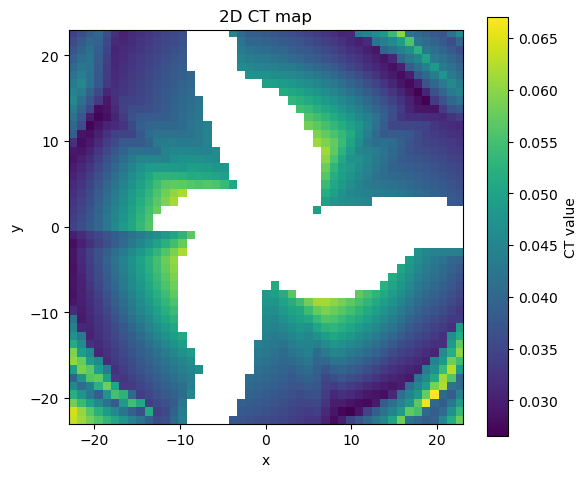

In [70]:
# Build a 2D map on the existing x/y grid
ct_map = np.full((n_gridy, n_gridx), np.nan)

ix = np.searchsorted(x_tmp, cal_ct_x)
iy = np.searchsorted(y_tmp, cal_ct_y)

in_bounds = (ix >= 0) & (ix < n_gridx) & (iy >= 0) & (iy < n_gridy)
finite = np.isfinite(cal_ct_value)
m = in_bounds & finite

ct_map[iy[m], ix[m]] = cal_ct_value[m]

# Plot
plt.figure(figsize=(6, 5))
im = plt.imshow(
    ct_map,
    origin="lower",
    extent=[x_range[0], x_range[1], y_range[0], y_range[1]],
    cmap="viridis",
    aspect="equal",
)
plt.colorbar(im, label="CT value")
plt.xlabel("x")
plt.ylabel("y")
plt.title("2D CT map")
plt.tight_layout()
plt.show()
